In [1]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
# Load Infrastructure dataset
infrastructure = pd.read_csv("infrastructure_points.csv")

# Load Roads dataset
roads = pd.read_csv("roads_processed.csv")

# Load Complaints dataset
complaints = pd.read_csv(
    "hyderabad_infrastructure_complaints_synthetic.csv"
)

print("All 3 datasets loaded successfully!")

All 3 datasets loaded successfully!


In [3]:
print("Infrastructure Shape:", infrastructure.shape)
print("Roads Shape:", roads.shape)
print("Complaints Shape:", complaints.shape)

Infrastructure Shape: (2083, 6)
Roads Shape: (93437, 8)
Complaints Shape: (1200, 15)


In [4]:
# Check Infrastructure dataset
print("INFRASTRUCTURE DATASET")
print(infrastructure.info())

# Check Roads dataset
print("\nROADS DATASET")
print(roads.info())

# Check Complaints dataset
print("\nCOMPLAINTS DATASET")
print(complaints.info())

INFRASTRUCTURE DATASET
<class 'pandas.DataFrame'>
RangeIndex: 2083 entries, 0 to 2082
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   osm_id     2083 non-null   str    
 1   category   2083 non-null   str    
 2   name       1495 non-null   str    
 3   subtype    2083 non-null   str    
 4   latitude   2083 non-null   float64
 5   longitude  2083 non-null   float64
dtypes: float64(2), str(4)
memory usage: 193.1 KB
None

ROADS DATASET
<class 'pandas.DataFrame'>
RangeIndex: 93437 entries, 0 to 93436
Data columns (total 8 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   osm_id     93437 non-null  str    
 1   road_name  7639 non-null   str    
 2   road_type  93437 non-null  str    
 3   maxspeed   3400 non-null   float64
 4   oneway     7215 non-null   str    
 5   latitude   93437 non-null  float64
 6   longitude  93437 non-null  float64
 7   length_km  93437 non-null  flo

In [5]:
# Step 3: Check missing values

print("Infrastructure Missing Values:")
print(infrastructure.isnull().sum())

print("\nRoads Missing Values:")
print(roads.isnull().sum())

print("\nComplaints Missing Values:")
print(complaints.isnull().sum())

Infrastructure Missing Values:
osm_id         0
category       0
name         588
subtype        0
latitude       0
longitude      0
dtype: int64

Roads Missing Values:
osm_id           0
road_name    85798
road_type        0
maxspeed     90037
oneway       86222
latitude         0
longitude        0
length_km        0
dtype: int64

Complaints Missing Values:
complaint_id                 0
complaint_type               0
latitude                     0
longitude                    0
grid_lat                     0
grid_lon                     0
complaint_date               0
nearby_building_count        0
nearby_fire_station_count    0
nearby_hospital_count        0
road_count                   0
total_road_length_km         0
resolution_days              0
status                       0
high_resolution_delay        0
dtype: int64


In [6]:
# Infrastructure: Fill missing names
infrastructure["name"] = infrastructure["name"].fillna("Unknown")

# Roads: Fill missing text values
roads["road_name"] = roads["road_name"].fillna("Unknown")
roads["oneway"] = roads["oneway"].fillna("Unknown")

# Roads: Fill missing speed values with median
roads["maxspeed"] = roads["maxspeed"].fillna(
    roads["maxspeed"].median()
)

# Complaints: No missing values, so no changes needed

print("Missing values handled successfully!")

print("\nInfrastructure missing values:")
print(infrastructure.isnull().sum())

print("\nRoads missing values:")
print(roads.isnull().sum())

print("\nComplaints missing values:")
print(complaints.isnull().sum())

Missing values handled successfully!

Infrastructure missing values:
osm_id       0
category     0
name         0
subtype      0
latitude     0
longitude    0
dtype: int64

Roads missing values:
osm_id       0
road_name    0
road_type    0
maxspeed     0
oneway       0
latitude     0
longitude    0
length_km    0
dtype: int64

Complaints missing values:
complaint_id                 0
complaint_type               0
latitude                     0
longitude                    0
grid_lat                     0
grid_lon                     0
complaint_date               0
nearby_building_count        0
nearby_fire_station_count    0
nearby_hospital_count        0
road_count                   0
total_road_length_km         0
resolution_days              0
status                       0
high_resolution_delay        0
dtype: int64


In [7]:
# Check duplicate records

print("Infrastructure duplicates:",
      infrastructure.duplicated().sum())

print("Roads duplicates:",
      roads.duplicated().sum())

print("Complaints duplicates:",
      complaints.duplicated().sum())

Infrastructure duplicates: 0
Roads duplicates: 0
Complaints duplicates: 0


In [8]:
print("Infrastructure Data Types:")
print(infrastructure.dtypes)

print("\nRoads Data Types:")
print(roads.dtypes)

print("\nComplaints Data Types:")
print(complaints.dtypes)

Infrastructure Data Types:
osm_id           str
category         str
name             str
subtype          str
latitude     float64
longitude    float64
dtype: object

Roads Data Types:
osm_id           str
road_name        str
road_type        str
maxspeed     float64
oneway           str
latitude     float64
longitude    float64
length_km    float64
dtype: object

Complaints Data Types:
complaint_id                     str
complaint_type                   str
latitude                     float64
longitude                    float64
grid_lat                     float64
grid_lon                     float64
complaint_date                   str
nearby_building_count          int64
nearby_fire_station_count      int64
nearby_hospital_count          int64
road_count                     int64
total_road_length_km         float64
resolution_days                int64
status                           str
high_resolution_delay          int64
dtype: object


In [9]:
# Convert complaint_date into datetime format

complaints["complaint_date"] = pd.to_datetime(
    complaints["complaint_date"],
    errors="coerce"
)

print(complaints["complaint_date"].dtype)

datetime64[us]


In [10]:
print("Missing dates:", complaints["complaint_date"].isnull().sum())

Missing dates: 0


In [11]:
print("Infrastructure:")
print(infrastructure[["latitude", "longitude"]].describe())

print("\nRoads:")
print(roads[["maxspeed", "latitude", "longitude", "length_km"]].describe())

print("\nComplaints:")
print(complaints.select_dtypes(include="number").describe())

Infrastructure:
          latitude    longitude
count  2083.000000  2083.000000
mean     17.433241    78.444410
std       0.049697     0.081602
min      17.259954    78.252448
25%      17.399000    78.384105
50%      17.437678    78.448572
75%      17.474827    78.508954
max      17.545873    78.632292

Roads:
           maxspeed      latitude     longitude     length_km
count  93437.000000  93437.000000  93437.000000  93437.000000
mean      59.816026     17.423494     78.467270      0.135182
std        3.039629      0.065241      0.075648      0.182821
min       10.000000     17.277727     78.238837      0.000500
25%       60.000000     17.366009     78.419121      0.044900
50%       60.000000     17.429850     78.468546      0.085000
75%       60.000000     17.480163     78.526544      0.158600
max      120.000000     17.557368     78.625485      8.205400

Complaints:
          latitude    longitude     grid_lat     grid_lon  \
count  1200.000000  1200.000000  1200.000000  1200.00000

In [12]:
print(complaints["complaint_type"].value_counts())

complaint_type
Road damage        301
Pothole            278
Drainage           247
Streetlight        231
Footpath damage    143
Name: count, dtype: int64


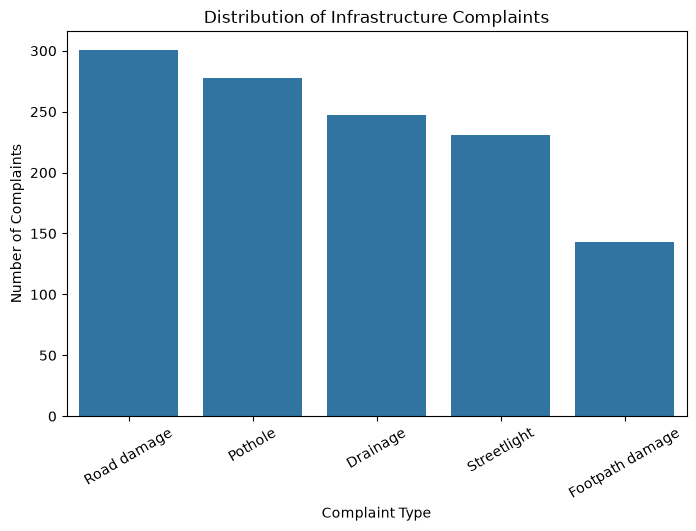

In [13]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=complaints,
    x="complaint_type",
    order=complaints["complaint_type"].value_counts().index
)

plt.title("Distribution of Infrastructure Complaints")
plt.xlabel("Complaint Type")
plt.ylabel("Number of Complaints")
plt.xticks(rotation=30)
plt.show()

In [14]:
print(complaints["status"].value_counts())

status
Pending     679
Resolved    521
Name: count, dtype: int64


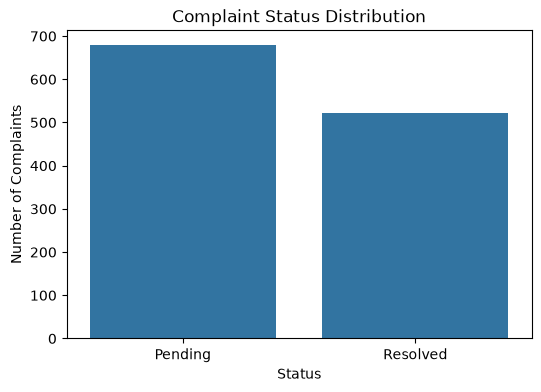

In [15]:
plt.figure(figsize=(6, 4))

sns.countplot(data=complaints, x="status")

plt.title("Complaint Status Distribution")
plt.xlabel("Status")
plt.ylabel("Number of Complaints")
plt.show()

In [16]:
print(complaints["high_resolution_delay"].value_counts())

high_resolution_delay
1    705
0    495
Name: count, dtype: int64


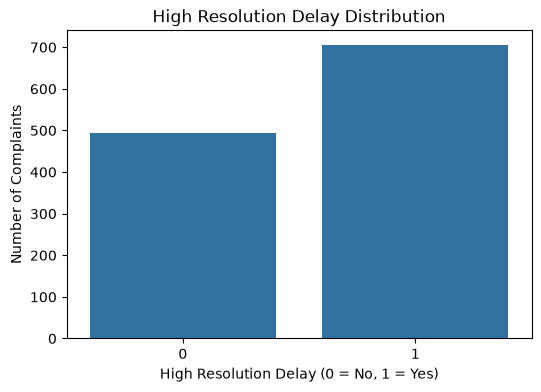

In [17]:
plt.figure(figsize=(6, 4))

sns.countplot(data=complaints, x="high_resolution_delay")

plt.title("High Resolution Delay Distribution")
plt.xlabel("High Resolution Delay (0 = No, 1 = Yes)")
plt.ylabel("Number of Complaints")
plt.show()

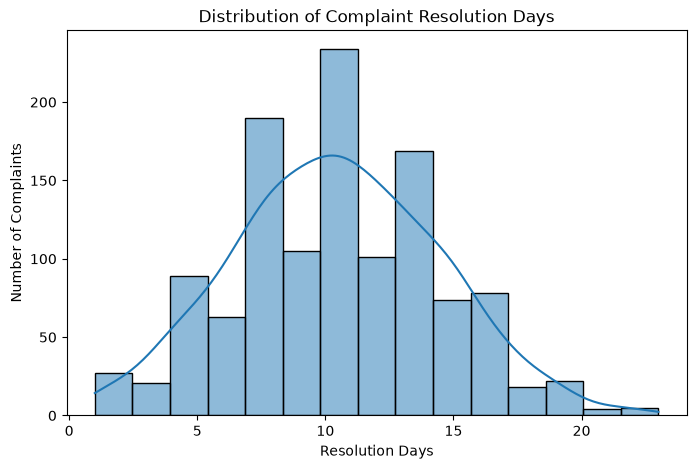

In [18]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=complaints,
    x="resolution_days",
    bins=15,
    kde=True
)

plt.title("Distribution of Complaint Resolution Days")
plt.xlabel("Resolution Days")
plt.ylabel("Number of Complaints")
plt.show()

In [19]:
avg_resolution = complaints.groupby("complaint_type")["resolution_days"].mean().sort_values(ascending=False)

print(avg_resolution)

complaint_type
Drainage           13.518219
Road damage        10.976744
Footpath damage    10.685315
Streetlight         9.155844
Pothole             8.107914
Name: resolution_days, dtype: float64


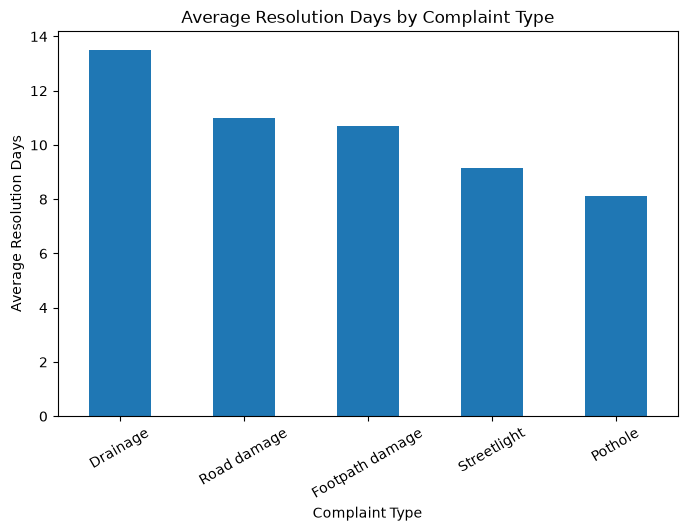

In [20]:
plt.figure(figsize=(8, 5))

avg_resolution.plot(kind="bar")

plt.title("Average Resolution Days by Complaint Type")
plt.xlabel("Complaint Type")
plt.ylabel("Average Resolution Days")
plt.xticks(rotation=30)
plt.show()

In [21]:
resource_columns = [
    "nearby_building_count",
    "nearby_fire_station_count",
    "nearby_hospital_count",
    "road_count"
]

print(complaints[resource_columns].mean())

nearby_building_count        12.013333
nearby_fire_station_count     0.124167
nearby_hospital_count         0.377500
road_count                    4.960000
dtype: float64


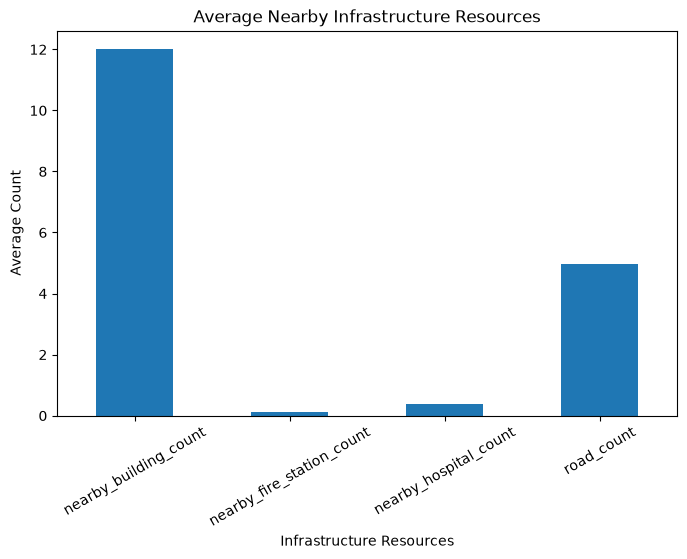

In [22]:
resource_means = complaints[resource_columns].mean()

plt.figure(figsize=(8, 5))

resource_means.plot(kind="bar")

plt.title("Average Nearby Infrastructure Resources")
plt.xlabel("Infrastructure Resources")
plt.ylabel("Average Count")
plt.xticks(rotation=30)
plt.show()

In [24]:
print(correlation["high_resolution_delay"].sort_values(ascending=False))

high_resolution_delay        1.000000
resolution_days              0.798053
road_count                   0.357038
latitude                     0.074846
grid_lat                     0.074846
nearby_building_count        0.010180
longitude                    0.001452
grid_lon                     0.001452
total_road_length_km        -0.007111
nearby_fire_station_count   -0.059224
nearby_hospital_count       -0.087868
Name: high_resolution_delay, dtype: float64


In [25]:
pd.crosstab(
    complaints["complaint_type"],
    complaints["high_resolution_delay"]
)

high_resolution_delay,0,1
complaint_type,,
Drainage,39,208
Footpath damage,52,91
Pothole,178,100
Road damage,106,195
Streetlight,120,111


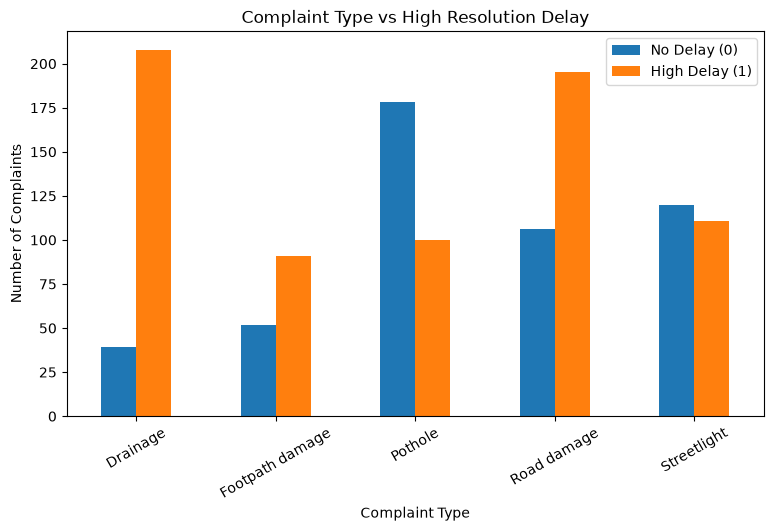

In [26]:
pd.crosstab(
    complaints["complaint_type"],
    complaints["high_resolution_delay"]
).plot(kind="bar", figsize=(9, 5))

plt.title("Complaint Type vs High Resolution Delay")
plt.xlabel("Complaint Type")
plt.ylabel("Number of Complaints")
plt.xticks(rotation=30)
plt.legend(["No Delay (0)", "High Delay (1)"])
plt.show()

In [27]:
print(infrastructure["category"].value_counts())

category
hospital        1073
building        1003
fire_station       7
Name: count, dtype: int64


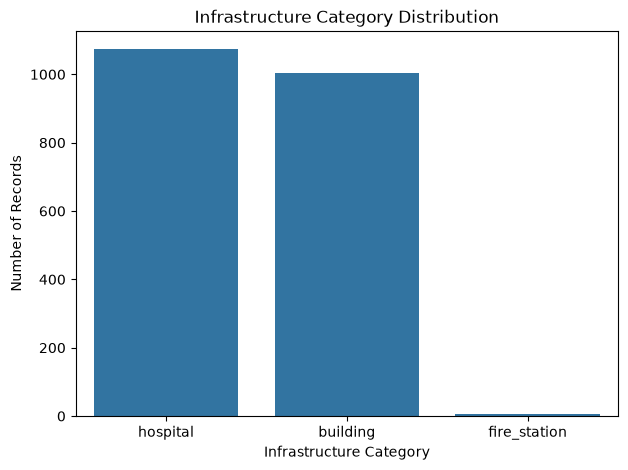

In [28]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=infrastructure,
    x="category",
    order=infrastructure["category"].value_counts().index
)

plt.title("Infrastructure Category Distribution")
plt.xlabel("Infrastructure Category")
plt.ylabel("Number of Records")
plt.show()

In [29]:
print(roads["road_type"].value_counts())

road_type
residential     85620
tertiary         3138
secondary        1780
primary          1468
trunk             836
unclassified      464
motorway          131
Name: count, dtype: int64


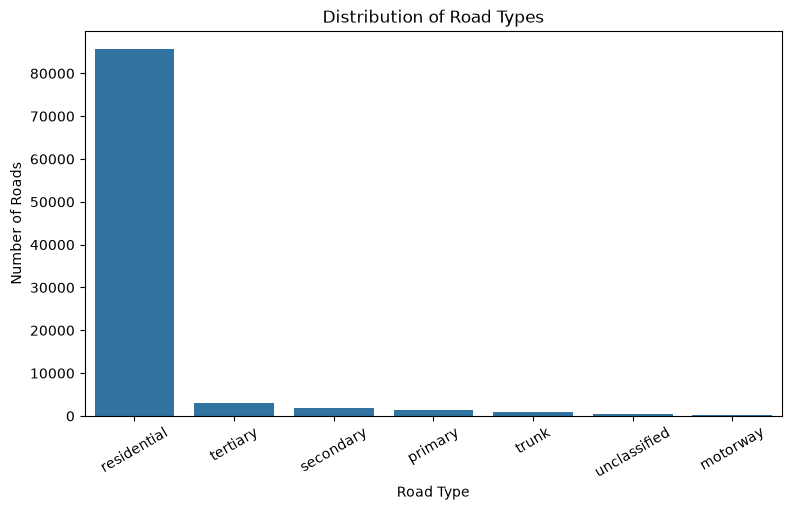

In [30]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=roads,
    x="road_type",
    order=roads["road_type"].value_counts().index
)

plt.title("Distribution of Road Types")
plt.xlabel("Road Type")
plt.ylabel("Number of Roads")
plt.xticks(rotation=30)
plt.show()

In [31]:
avg_road_length = roads.groupby("road_type")["length_km"].mean().sort_values(ascending=False)

print(avg_road_length)

road_type
motorway        0.348636
trunk           0.315914
tertiary        0.293054
primary         0.290748
secondary       0.289422
unclassified    0.213471
residential     0.121007
Name: length_km, dtype: float64


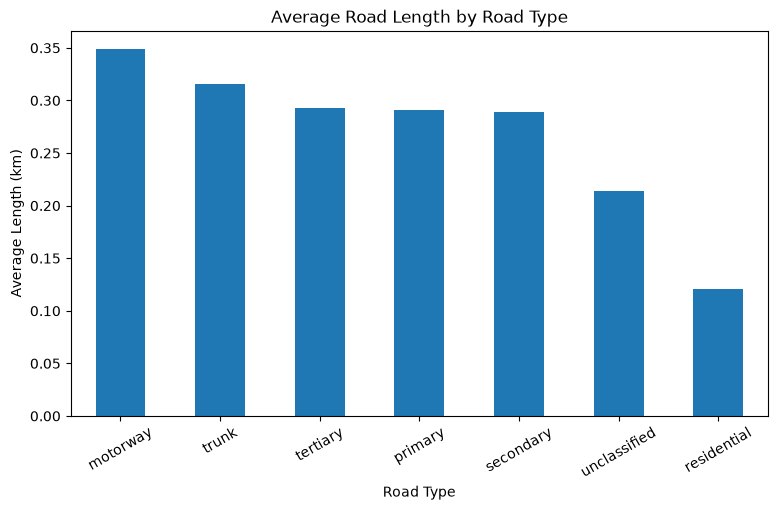

In [32]:
plt.figure(figsize=(9, 5))

avg_road_length.plot(kind="bar")

plt.title("Average Road Length by Road Type")
plt.xlabel("Road Type")
plt.ylabel("Average Length (km)")
plt.xticks(rotation=30)
plt.show()

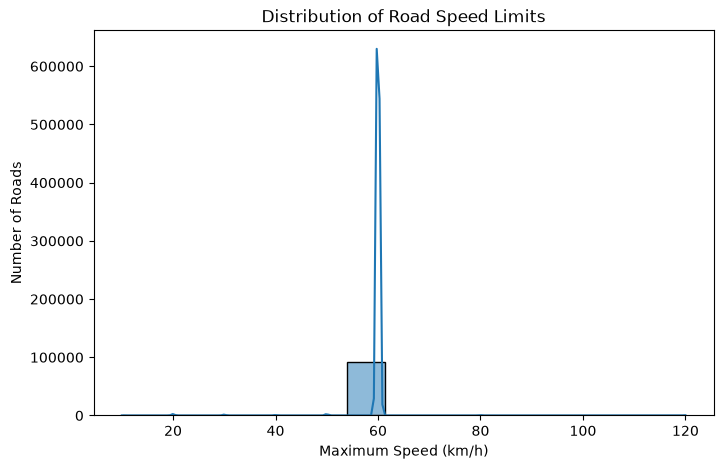

In [33]:
plt.figure(figsize=(8, 5))

sns.histplot(data=roads, x="maxspeed", bins=15, kde=True)

plt.title("Distribution of Road Speed Limits")
plt.xlabel("Maximum Speed (km/h)")
plt.ylabel("Number of Roads")
plt.show()

In [34]:
avg_speed = roads.groupby("road_type")["maxspeed"].mean().sort_values(ascending=False)

print(avg_speed)

road_type
motorway        88.396947
residential     59.843144
trunk           59.581340
primary         59.284741
unclassified    59.224138
tertiary        59.107712
secondary       58.359551
Name: maxspeed, dtype: float64


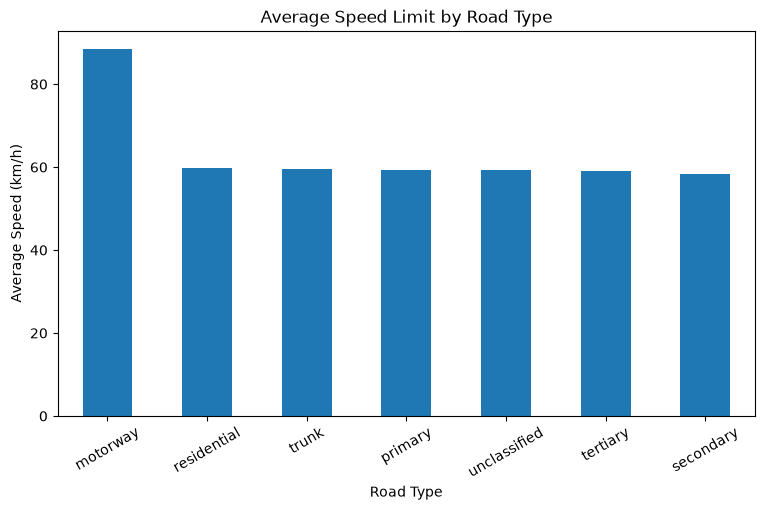

In [35]:
plt.figure(figsize=(9, 5))

avg_speed.plot(kind="bar")

plt.title("Average Speed Limit by Road Type")
plt.xlabel("Road Type")
plt.ylabel("Average Speed (km/h)")
plt.xticks(rotation=30)
plt.show()

In [36]:
print(roads["oneway"].value_counts())

oneway
Unknown    86222
yes         6830
no           385
Name: count, dtype: int64


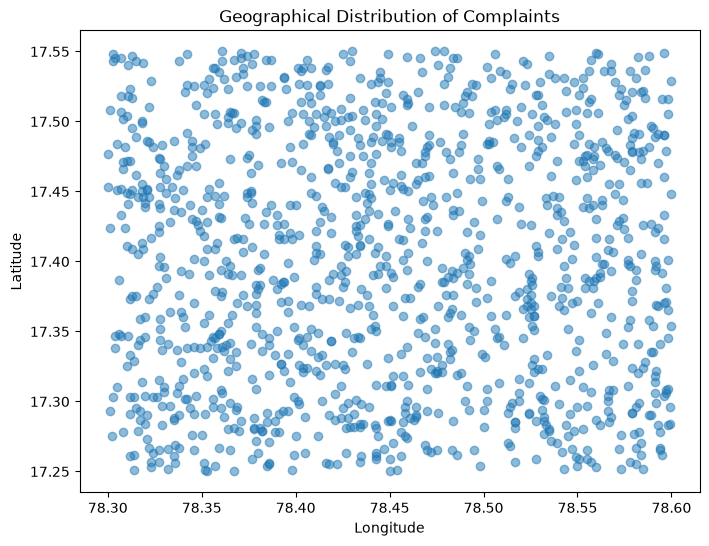

In [37]:
plt.figure(figsize=(8, 6))

plt.scatter(
    complaints["longitude"],
    complaints["latitude"],
    alpha=0.5
)

plt.title("Geographical Distribution of Complaints")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.show()

In [38]:
print(
    complaints["high_resolution_delay"]
    .value_counts(normalize=True) * 100
)

high_resolution_delay
1    58.75
0    41.25
Name: proportion, dtype: float64


In [39]:
print(complaints.columns.tolist())

['complaint_id', 'complaint_type', 'latitude', 'longitude', 'grid_lat', 'grid_lon', 'complaint_date', 'nearby_building_count', 'nearby_fire_station_count', 'nearby_hospital_count', 'road_count', 'total_road_length_km', 'resolution_days', 'status', 'high_resolution_delay']


In [40]:
# Select input features
features = [
    "complaint_type",
    "latitude",
    "longitude",
    "nearby_building_count",
    "nearby_fire_station_count",
    "nearby_hospital_count",
    "road_count",
    "total_road_length_km"
]

X = complaints[features]

# Select target
y = complaints["high_resolution_delay"]

print("Input features shape:", X.shape)
print("Target shape:", y.shape)

Input features shape: (1200, 8)
Target shape: (1200,)


In [41]:
# Separate categorical and numerical columns

categorical_features = ["complaint_type"]

numerical_features = [
    "latitude",
    "longitude",
    "nearby_building_count",
    "nearby_fire_station_count",
    "nearby_hospital_count",
    "road_count",
    "total_road_length_km"
]

print("Categorical features:", categorical_features)
print("Numerical features:", numerical_features)

Categorical features: ['complaint_type']
Numerical features: ['latitude', 'longitude', 'nearby_building_count', 'nearby_fire_station_count', 'nearby_hospital_count', 'road_count', 'total_road_length_km']


In [42]:
from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(handle_unknown="ignore")

encoded_data = encoder.fit_transform(
    X[categorical_features]
)

print("Encoded shape:", encoded_data.shape)
print(encoder.get_feature_names_out(categorical_features))

Encoded shape: (1200, 5)
['complaint_type_Drainage' 'complaint_type_Footpath damage'
 'complaint_type_Pothole' 'complaint_type_Road damage'
 'complaint_type_Streetlight']


In [43]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (960, 8)
Testing data: (240, 8)


In [44]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [45]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

# Create Logistic Regression model
logistic_model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

# Train the model
logistic_model.fit(X_train, y_train)

print("Logistic Regression training completed!")

Logistic Regression training completed!


In [46]:
from sklearn.tree import DecisionTreeClassifier

# Create Decision Tree model
decision_tree_model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", DecisionTreeClassifier(random_state=42))
])

# Train the model
decision_tree_model.fit(X_train, y_train)

print("Decision Tree training completed!")

Decision Tree training completed!


In [47]:
from sklearn.ensemble import RandomForestClassifier

# Create Random Forest model
random_forest_model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ))
])

# Train the model
random_forest_model.fit(X_train, y_train)

print("Random Forest training completed!")

Random Forest training completed!


In [48]:
from sklearn.neighbors import KNeighborsClassifier

# Create KNN model
knn_model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", KNeighborsClassifier(n_neighbors=5))
])

# Train the model
knn_model.fit(X_train, y_train)

print("KNN training completed!")

KNN training completed!


In [49]:
from sklearn.svm import SVC

# Create SVM model
svm_model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", SVC())
])

# Train the model
svm_model.fit(X_train, y_train)

print("SVM training completed!")


SVM training completed!


In [50]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

models = {
    "Logistic Regression": logistic_model,
    "Decision Tree": decision_tree_model,
    "Random Forest": random_forest_model,
    "KNN": knn_model,
    "SVM": svm_model
}

results = []

for name, model in models.items():
    y_pred = model.predict(X_test)

    results.append({
        "Algorithm": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1 Score": f1_score(y_test, y_pred, zero_division=0)
    })

results_df = pd.DataFrame(results)

print(results_df.round(3))

             Algorithm  Accuracy  Precision  Recall  F1 Score
0  Logistic Regression     0.696      0.715   0.801     0.756
1        Decision Tree     0.608      0.677   0.638     0.657
2        Random Forest     0.650      0.679   0.766     0.720
3                  KNN     0.654      0.675   0.794     0.730
4                  SVM     0.692      0.701   0.830     0.760


In [51]:
results_df.to_csv("complaints_model_comparison.csv", index=False)
print("Complaints model results saved!")

Complaints model results saved!


In [52]:
svm_model.fit(X_train, y_train)

print("Best model (SVM) trained successfully!")

Best model (SVM) trained successfully!


In [53]:
y_pred_svm = svm_model.predict(X_test)

print("SVM Accuracy:", accuracy_score(y_test, y_pred_svm))
print("SVM Precision:", precision_score(y_test, y_pred_svm))
print("SVM Recall:", recall_score(y_test, y_pred_svm))
print("SVM F1 Score:", f1_score(y_test, y_pred_svm))

SVM Accuracy: 0.6916666666666667
SVM Precision: 0.7005988023952096
SVM Recall: 0.8297872340425532
SVM F1 Score: 0.7597402597402597


In [55]:
#INFRASTRUCTURE
from sklearn.preprocessing import StandardScaler

# Select useful numerical features
infra_features = infrastructure[["latitude", "longitude"]]

# Scale the data
infra_scaler = StandardScaler()
infra_scaled = infra_scaler.fit_transform(infra_features)

print("Infrastructure data preprocessing completed!")
print("Scaled data shape:", infra_scaled.shape)

Infrastructure data preprocessing completed!
Scaled data shape: (2083, 2)


In [57]:
#KMEANS
from sklearn.cluster import KMeans

kmeans_model = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

kmeans_labels = kmeans_model.fit_predict(infra_scaled)

print("K-Means clustering completed!")
print("Number of clusters:", len(set(kmeans_labels)))

K-Means clustering completed!
Number of clusters: 3


In [58]:
#DBSCAN
from sklearn.cluster import DBSCAN

dbscan_model = DBSCAN(
    eps=0.3,
    min_samples=5
)

dbscan_labels = dbscan_model.fit_predict(infra_scaled)

print("DBSCAN clustering completed!")
print("Number of clusters:", len(set(dbscan_labels)) - (1 if -1 in dbscan_labels else 0))
print("Noise points:", list(dbscan_labels).count(-1))

DBSCAN clustering completed!
Number of clusters: 4
Noise points: 24


In [59]:
#COMAPRING BOTH ALGORITHMS
from sklearn.metrics import silhouette_score, davies_bouldin_score

# K-Means evaluation
kmeans_sil = silhouette_score(infra_scaled, kmeans_labels)
kmeans_db = davies_bouldin_score(infra_scaled, kmeans_labels)

# DBSCAN evaluation (exclude noise points)
dbscan_mask = dbscan_labels != -1
dbscan_data = infra_scaled[dbscan_mask]
dbscan_valid_labels = dbscan_labels[dbscan_mask]

dbscan_sil = silhouette_score(dbscan_data, dbscan_valid_labels)
dbscan_db = davies_bouldin_score(
    dbscan_data, dbscan_valid_labels
)

# Comparison
infra_results = pd.DataFrame({
    "Algorithm": ["K-Means", "DBSCAN"],
    "Silhouette Score": [kmeans_sil, dbscan_sil],
    "Davies-Bouldin Score": [kmeans_db, dbscan_db]
})

print(infra_results.round(3))

  Algorithm  Silhouette Score  Davies-Bouldin Score
0   K-Means             0.390                 0.933
1    DBSCAN             0.034                 0.545


In [62]:
# Compare algorithms using Silhouette Score

best_algorithm = infra_results.loc[
    infra_results["Silhouette Score"].idxmax(),
    "Algorithm"
]

print("Algorithm Comparison:")
print(infra_results.round(3))

print("\nBest Algorithm:", best_algorithm)

if best_algorithm == "K-Means":
    print("\nConclusion:")
    print("K-Means is selected as the best clustering algorithm")
    print("because it achieved the highest Silhouette Score.")
    print("It provides better cluster separation than DBSCAN.")

Algorithm Comparison:
  Algorithm  Silhouette Score  Davies-Bouldin Score
0   K-Means             0.390                 0.933
1    DBSCAN             0.034                 0.545

Best Algorithm: K-Means

Conclusion:
K-Means is selected as the best clustering algorithm
because it achieved the highest Silhouette Score.
It provides better cluster separation than DBSCAN.


In [67]:
from sklearn.cluster import KMeans

# Train final K-Means model
final_infra_kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

final_infra_labels = final_infra_kmeans.fit_predict(infra_scaled)

print("Final K-Means model trained successfully!")

Final K-Means model trained successfully!


In [74]:
import pandas as pd

cluster_counts = pd.Series(final_infra_labels).value_counts().sort_index()

print("Final Infrastructure K-Means Results")
print("------------------------------------")
print("Total Locations:", len(final_infra_labels))
print("Total Clusters:", len(cluster_counts))
print("\nLocations in Each Cluster:")
print(cluster_counts)

Final Infrastructure K-Means Results
------------------------------------
Total Locations: 2083
Total Clusters: 3

Locations in Each Cluster:
0    607
1    756
2    720
Name: count, dtype: int64


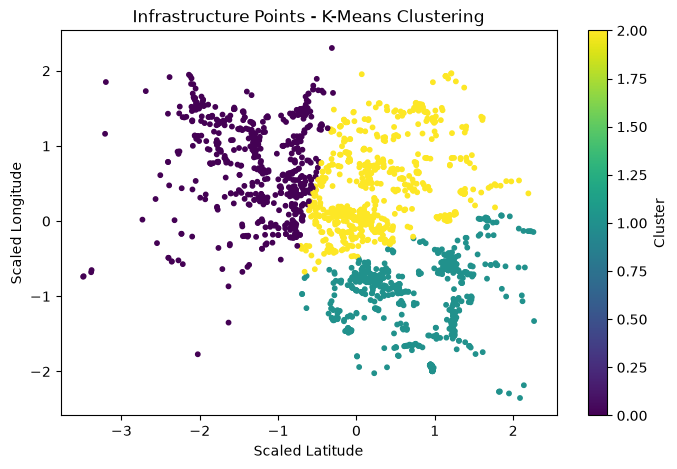

In [69]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(
    infra_scaled[:, 0],
    infra_scaled[:, 1],
    c=kmeans_labels,
    cmap="viridis",
    s=10
)

plt.title("Infrastructure Points - K-Means Clustering")
plt.xlabel("Scaled Latitude")
plt.ylabel("Scaled Longitude")
plt.colorbar(label="Cluster")
plt.show()

In [68]:
import joblib

joblib.dump(final_infra_kmeans, "best_infrastructure_kmeans.pkl")

print("Best K-Means model saved successfully!")

Best K-Means model saved successfully!


In [71]:
# Save comparison
infra_results.to_csv(
    "infrastructure_model_comparison.csv",
    index=False
)

# Save final cluster assignments
infrastructure["Final_KMeans_Cluster"] = final_infra_labels

infrastructure.to_csv(
    "infrastructure_final_results.csv",
    index=False
)

print("All Infrastructure results saved successfully!")

All Infrastructure results saved successfully!


In [75]:
# Select 10,000 random records
roads_sample = roads.sample(n=10000, random_state=42)

# Select geographical features
road_features = roads_sample[["latitude", "longitude"]]

# Scale the data
road_scaler = StandardScaler()
road_scaled = road_scaler.fit_transform(road_features)

print("Roads data preprocessing completed!")
print("Original dataset shape:", roads.shape)
print("Sample shape:", roads_sample.shape)
print("Scaled data shape:", road_scaled.shape)

Roads data preprocessing completed!
Original dataset shape: (93437, 8)
Sample shape: (10000, 8)
Scaled data shape: (10000, 2)


In [76]:
from sklearn.cluster import KMeans

road_kmeans_model = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

road_kmeans_labels = road_kmeans_model.fit_predict(road_scaled)

print("Roads K-Means clustering completed!")
print("Number of clusters:", len(set(road_kmeans_labels)))

Roads K-Means clustering completed!
Number of clusters: 3


In [77]:
from sklearn.cluster import DBSCAN

road_dbscan_model = DBSCAN(
    eps=0.3,
    min_samples=5
)

road_dbscan_labels = road_dbscan_model.fit_predict(road_scaled)

print("Roads DBSCAN clustering completed!")

print(
    "Number of clusters:",
    len(set(road_dbscan_labels)) - (1 if -1 in road_dbscan_labels else 0)
)

print("Noise points:", list(road_dbscan_labels).count(-1))

Roads DBSCAN clustering completed!
Number of clusters: 1
Noise points: 0


In [78]:
road_dbscan_model = DBSCAN(
    eps=0.1,
    min_samples=5
)

road_dbscan_labels = road_dbscan_model.fit_predict(road_scaled)

print("DBSCAN clustering completed!")

print(
    "Number of clusters:",
    len(set(road_dbscan_labels)) - (1 if -1 in road_dbscan_labels else 0)
)

print("Noise points:", list(road_dbscan_labels).count(-1))

DBSCAN clustering completed!
Number of clusters: 6
Noise points: 16


In [79]:
from sklearn.metrics import silhouette_score, davies_bouldin_score

# K-Means evaluation
road_kmeans_sil = silhouette_score(
    road_scaled, road_kmeans_labels
)

road_kmeans_db = davies_bouldin_score(
    road_scaled, road_kmeans_labels
)

# DBSCAN evaluation (exclude noise points)
road_mask = road_dbscan_labels != -1

road_valid_data = road_scaled[road_mask]
road_valid_labels = road_dbscan_labels[road_mask]

road_dbscan_sil = silhouette_score(
    road_valid_data, road_valid_labels
)

road_dbscan_db = davies_bouldin_score(
    road_valid_data, road_valid_labels
)

# Comparison table
road_results = pd.DataFrame({
    "Algorithm": ["K-Means", "DBSCAN"],
    "Silhouette Score": [
        road_kmeans_sil, road_dbscan_sil
    ],
    "Davies-Bouldin Score": [
        road_kmeans_db, road_dbscan_db
    ]
})

print(road_results.round(3))

  Algorithm  Silhouette Score  Davies-Bouldin Score
0   K-Means             0.421                 0.820
1    DBSCAN            -0.105                 0.724


In [80]:
best_road_algorithm = road_results.loc[
    road_results["Silhouette Score"].idxmax(),
    "Algorithm"
]

print("Roads Algorithm Comparison:")
print(road_results.round(3))

print("\nBest Algorithm:", best_road_algorithm)

print("\nConclusion:")
print("K-Means is selected as the best clustering algorithm")
print("because it achieved the highest Silhouette Score.")
print("It provides better cluster separation than DBSCAN.")

Roads Algorithm Comparison:
  Algorithm  Silhouette Score  Davies-Bouldin Score
0   K-Means             0.421                 0.820
1    DBSCAN            -0.105                 0.724

Best Algorithm: K-Means

Conclusion:
K-Means is selected as the best clustering algorithm
because it achieved the highest Silhouette Score.
It provides better cluster separation than DBSCAN.


In [81]:
from sklearn.cluster import KMeans

final_road_kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

final_road_labels = final_road_kmeans.fit_predict(road_scaled)

print("Final Roads K-Means model trained successfully!")

Final Roads K-Means model trained successfully!


In [82]:
import joblib

joblib.dump(
    final_road_kmeans,
    "best_roads_kmeans.pkl"
)

print("Best Roads K-Means model saved successfully!")

Best Roads K-Means model saved successfully!


In [83]:
# Save algorithm comparison
road_results.to_csv(
    "roads_model_comparison.csv",
    index=False
)

# Save final cluster assignments
roads_sample = roads_sample.copy()
roads_sample["Final_KMeans_Cluster"] = final_road_labels

roads_sample.to_csv(
    "roads_final_results.csv",
    index=False
)

print("All Roads results saved successfully!")

All Roads results saved successfully!


In [84]:
print("Final Roads K-Means Results")
print("---------------------------")
print("Total Road Locations:", len(final_road_labels))
print("Total Clusters:", len(set(final_road_labels)))

print("\nLocations in Each Cluster:")
print(pd.Series(final_road_labels).value_counts().sort_index())

Final Roads K-Means Results
---------------------------
Total Road Locations: 10000
Total Clusters: 3

Locations in Each Cluster:
0    3196
1    2558
2    4246
Name: count, dtype: int64


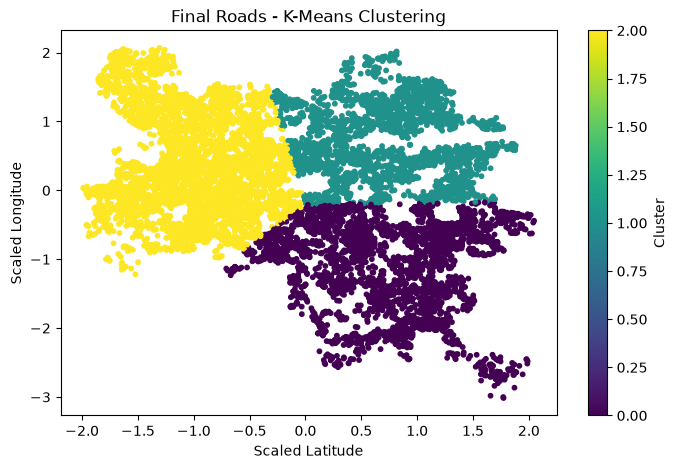

In [85]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(
    road_scaled[:, 0],
    road_scaled[:, 1],
    c=final_road_labels,
    cmap="viridis",
    s=10
)

plt.title("Final Roads - K-Means Clustering")
plt.xlabel("Scaled Latitude")
plt.ylabel("Scaled Longitude")
plt.colorbar(label="Cluster")
plt.show()

In [86]:
print("Final Roads K-Means Results")
print("---------------------------")
print("Total Road Locations:", len(final_road_labels))
print("Total Clusters:", len(set(final_road_labels)))

print("\nLocations in Each Cluster:")
print(pd.Series(final_road_labels).value_counts().sort_index())

Final Roads K-Means Results
---------------------------
Total Road Locations: 10000
Total Clusters: 3

Locations in Each Cluster:
0    3196
1    2558
2    4246
Name: count, dtype: int64


In [87]:
final_comparison = pd.DataFrame({
    "Dataset": [
        "Infrastructure Complaints",
        "Infrastructure Points",
        "Roads"
    ],
    "Best Algorithm": [
        "SVM",
        "K-Means",
        "K-Means"
    ],
    "Evaluation Metric": [
        "F1 Score",
        "Silhouette Score",
        "Silhouette Score"
    ],
    "Best Score": [
        0.760,
        0.390,
        0.421
    ]
})

print("FINAL MODEL COMPARISON")
print("----------------------")
print(final_comparison)

FINAL MODEL COMPARISON
----------------------
                     Dataset Best Algorithm Evaluation Metric  Best Score
0  Infrastructure Complaints            SVM          F1 Score       0.760
1      Infrastructure Points        K-Means  Silhouette Score       0.390
2                      Roads        K-Means  Silhouette Score       0.421


In [88]:
print("COMPLAINTS DATASET")
print("------------------")
display(results_df.round(3))

print("\nINFRASTRUCTURE POINTS DATASET")
print("-----------------------------")
display(infra_results.round(3))

print("\nROADS DATASET")
print("-------------")
display(road_results.round(3))

COMPLAINTS DATASET
------------------


,Algorithm,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.696,0.715,0.801,0.756
1,Decision Tree,0.608,0.677,0.638,0.657
2,Random Forest,0.650,0.679,0.766,0.720
3,KNN,0.654,0.675,0.794,0.730
4,SVM,0.692,0.701,0.830,0.760



INFRASTRUCTURE POINTS DATASET
-----------------------------


,Algorithm,Silhouette Score,Davies-Bouldin Score
0,K-Means,0.390,0.933
1,DBSCAN,0.034,0.545



ROADS DATASET
-------------


,Algorithm,Silhouette Score,Davies-Bouldin Score
0,K-Means,0.421,0.820
1,DBSCAN,-0.105,0.724
